# 01 · Veri Hazırlama — Çilek Hastalığı (Görev 13)

**Amaç:** Strawberry Disease Detection Dataset'i (Afzaal ve ark., 2021) indirmek, etiketleri denetleyip kurallı biçimde düzeltmek,
keşifsel analiz yapmak, bölmeler arası sızıntıyı ölçmek ve etiketleri üç biçime dönüştürüp dönüşümü doğrulamak:

1. Ultralytics **sınıflandırma** klasörleri (`data/processed/cls`)
2. **YOLO-seg** (`data/processed/yoloseg`)
3. **COCO** — RF-DETR / Roboflow düzeni (`data/processed/coco`)

Tüm hesaplar `src/` altındaki fonksiyonlarla yapılır; yerel panel (`app/`) ve rapor aynı çıktıları (`data/derived/`) kullanır.
Notebook baştan sona **Runtime → Run all** ile çalışır; GPU gerekmez.

## 0 · Ortam

In [1]:
import os, sys, platform, random, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Proje klasörü Drive'da (GitHub'dan klonlanmış ya da yüklenmiş): MyDrive/odev13
    os.environ.setdefault("ODEV13_ROOT", "/content/drive/MyDrive/odev13")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imagehash", "kagglehub", "pycocotools", "shapely"], check=True)
    ROOT = Path(os.environ["ODEV13_ROOT"])
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
    os.environ.setdefault("ODEV13_ROOT", str(ROOT))

sys.path.insert(0, str(ROOT))
assert (ROOT / "src" / "pipeline.py").exists(), f"Proje kodu bulunamadı: {ROOT}"

from src import config as C
random.seed(C.SEED)
import numpy as np; np.random.seed(C.SEED)

import pandas as pd, matplotlib, shapely, imagehash, pycocotools, PIL
print("Proje kökü :", ROOT)
print("Python     :", platform.python_version(), "| Colab:", IN_COLAB)
print("numpy", np.__version__, "| pandas", pd.__version__, "| shapely", shapely.__version__,
      "| imagehash", imagehash.__version__, "| Pillow", PIL.__version__)

Proje kökü : /Users/toprakozkale/Desktop/derin_ogrenme_yl_odev
Python     : 3.13.18 | Colab: False
numpy 2.5.4 | pandas 3.1.1 | shapely 2.2.0 | imagehash 4.3.2 | Pillow 13.0.0


## 1 · İndirme

Veri Kaggle'dan `kagglehub` ile iner (`usmanafzaal/strawberry-disease-detection-dataset`, sürüm 1).
Colab'da Kaggle kimliği için sol menüdeki 🔑 **Secrets** bölümüne `KAGGLE_USERNAME` ve `KAGGLE_KEY` eklenir.
Yerelde `~/.kaggle/kaggle.json` kullanılır. Veri zaten iniyse bu adım atlanır.

In [2]:
if IN_COLAB and not os.environ.get("KAGGLE_KEY"):
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

from src.pipeline import download
raw = download()
print("Ham veri:", raw)
for d in sorted(p for p in raw.iterdir() if p.is_dir()):
    print(f"  {d.name:32s} {len(list(d.rglob('*.jpg'))):5d} jpg  {len(list(d.rglob('*.json'))):5d} json")

Ham veri: /Users/toprakozkale/Desktop/derin_ogrenme_yl_odev/data/raw/strawberry
  Test Disease Severity Level        743 jpg    743 json
  test                               743 jpg    743 json
  train                             1450 jpg   1450 json
  val                                307 jpg    307 json


## 2 · Tüm hat: denetim → istatistik → sızıntı → dönüşüm → doğrulama

`src.pipeline.run()` sırasıyla:
- LabelMe JSON'ları okur, poligonları kurallarla düzeltir (kendini kesen → `make_valid` + en büyük parça; görüntü dışı → kırpma;
  3'ten az nokta / sıfır alan → atma) ve her işlemi kaydeder,
- bölme ve sınıf istatistiklerini hesaplar,
- MD5 ile birebir, pHash ile yakın-yinelenen görüntüleri bulur, eşiğe göre sızıntıyı ölçer ve **temiz test** listesini çıkarır,
- üç biçime dönüştürür ve her örneği geri okuyarak IoU ile doğrular.

In [3]:
from src.pipeline import run
summary = run(threshold=C.PHASH_THRESHOLD)

1) Etiketler okunuyor ve denetleniyor…


2) İstatistikler…


3) Yinelenen / yakın-yinelenen görüntüler (pHash)…


4) Bölme listeleri…


5) Dönüşümler: sınıflandırma klasörleri, YOLO-seg, COCO…


6) Doğrulama: her formattan maske geri üretilip kaynakla karşılaştırılıyor…


Bitti (14.0 sn). Özet: /Users/toprakozkale/Desktop/derin_ogrenme_yl_odev/data/derived/summary.json


## 3 · Keşifsel analiz

In [4]:
S = summary["stats"]
tab = pd.DataFrame({sp: {"görüntü": S[sp]["n_images"], "örnek (poligon)": S[sp]["n_instances"],
                         "görüntü başına örnek (ort.)": round(S[sp]["instances_per_image"]["mean"], 2),
                         "en çok örnek": S[sp]["instances_per_image"]["max"],
                         "çok sınıflı görüntü": S[sp]["n_multiclass_images"],
                         "görüntü boyutları": ", ".join(S[sp]["image_sizes"])} for sp in C.SPLITS})
tab

,train,val,test
görüntü,1450,307,743
örnek (poligon),3540,751,1416
görüntü başına örnek (ort.),2.44,2.45,1.91
en çok örnek,15,12,17
çok sınıflı görüntü,6,0,3
görüntü boyutları,419x419,419x419,419x419


In [5]:
cls_tab = pd.DataFrame({(sp, k): S[sp][key] for sp in C.SPLITS
                        for k, key in (("görüntü", "images_per_label"), ("örnek", "instances_per_class"))})
cls_tab.index.name = "sınıf"
cls_tab

train           val          test      
                      görüntü örnek görüntü örnek görüntü örnek
sınıf                                                          
Angular Leafspot          245   294      43    52     147   193
Anthracnose Fruit Rot      52    89      12    17      33    58
Blossom Blight            118   186      29    44      62    70
Gray Mold                 254   332      77   108     145   158
Leaf Spot                 382  1365      71   257     162   478
Powdery Mildew Fruit       80   164      12    18      43   116
Powdery Mildew Leaf       319  1110      63   255     151   343

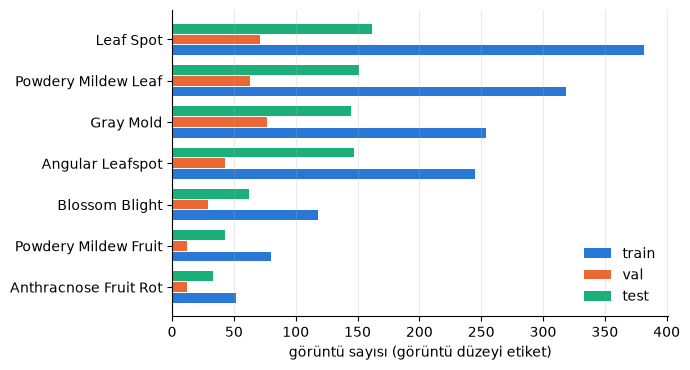

In [6]:
import matplotlib.pyplot as plt
FIG = ROOT / "rapor" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SPLIT_COLOR = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}

order = sorted(C.CLASSES, key=lambda c: S["train"]["images_per_label"][c])
fig, ax = plt.subplots(figsize=(7, 3.8))
h = 0.26
for k, sp in enumerate(C.SPLITS):
    y = np.arange(len(order)) + (k - 1) * h
    ax.barh(y, [S[sp]["images_per_label"][c] for c in order], height=h * 0.9, color=SPLIT_COLOR[sp], label=sp)
ax.set_yticks(np.arange(len(order)), order); ax.set_xlabel("görüntü sayısı (görüntü düzeyi etiket)")
ax.legend(frameon=False, loc="lower right"); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=.25)
plt.tight_layout(); plt.savefig(FIG / "sinif_dagilimi.pdf"); plt.savefig(FIG / "sinif_dagilimi.png", dpi=200); plt.show()

### Örnek görüntüler (her sınıftan biri, poligon bindirmeli)

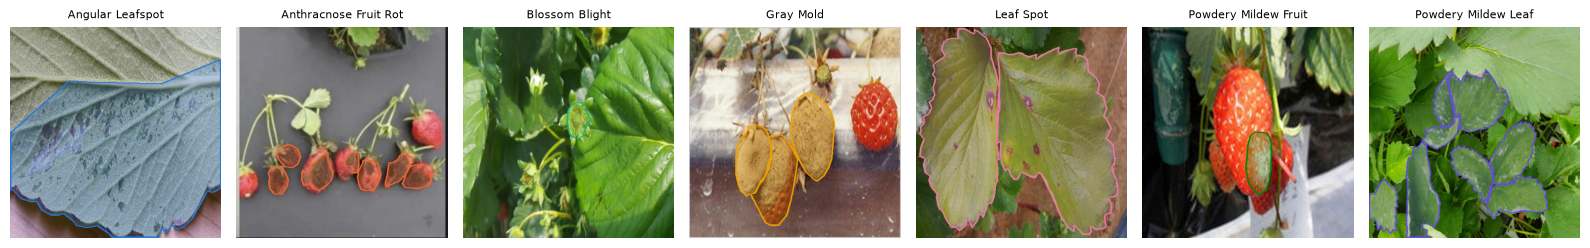

In [7]:
from PIL import Image, ImageDraw
from src.dataset import load_record
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
COL = {c: PAL[i] for i, c in enumerate(C.CLASSES)}

def overlay(split, stem):
    r = load_record(C.RAW / split / f"{stem}.json", split)
    im = Image.open(r.image_path).convert("RGBA"); lay = Image.new("RGBA", im.size); d = ImageDraw.Draw(lay)
    for i in r.instances:
        rgb = tuple(int(COL[i.label][k:k + 2], 16) for k in (1, 3, 5))
        d.polygon([tuple(p) for p in i.points], fill=rgb + (70,), outline=rgb + (255,), width=3)
    return Image.alpha_composite(im, lay).convert("RGB")

fig, axes = plt.subplots(1, 7, figsize=(16, 2.8))
for ax, c in zip(axes, C.CLASSES):
    stem = sorted(p.stem for p in (C.RAW / "train").glob(f"{C.CLASS_SLUG[c]}*.json"))[3]
    ax.imshow(overlay("train", stem)); ax.set_title(c, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "ornekler.png", dpi=110); plt.show()

## 4 · Etiket denetimi

**Görüntü düzeyi etiket kuralı (sınıflandırma için):** Görüntüdeki tüm örnekler tek sınıftansa o sınıf; birden fazla sınıf varsa toplam poligon alanı en büyük olan sınıf.

In [8]:
print("Görüntü düzeyi etiket kuralı:", C.IMAGE_LABEL_RULE)
print("İşlem sayıları:", summary["label_issue_counts"])
issues = pd.read_csv(C.DERIVED / "label_issues.csv"); issues

Görüntü düzeyi etiket kuralı: Görüntüdeki tüm örnekler tek sınıftansa o sınıf; birden fazla sınıf varsa toplam poligon alanı en büyük olan sınıf.
İşlem sayıları: {'kendini_kesen:onarildi': 12, 'goruntu_disi:kirpildi': 4}


,split,stem,label,islem,alan_ham,alan_son
0,train,angular_leafspot283,Angular Leafspot,kendini_kesen:onarildi:parca=1:tutulan_oran=1.000,91218.1,91218.1
1,train,angular_leafspot299,Angular Leafspot,kendini_kesen:onarildi:parca=1:tutulan_oran=1.000,34485.3,34485.1
2,train,angular_leafspot65,Angular Leafspot,goruntu_disi:kirpildi,96480.0,96211.7
3,train,gray_mold270,Gray Mold,kendini_kesen:onarildi:parca=2:tutulan_oran=1.000,10793.6,10794.0
4,train,gray_mold332,Gray Mold,kendini_kesen:onarildi:parca=1:tutulan_oran=1.000,6058.2,6058.1
5,train,leaf_spot197,Leaf Spot,goruntu_disi:kirpildi,8667.0,8563.1
6,train,leaf_spot255,Leaf Spot,goruntu_disi:kirpildi,22232.8,22217.6
7,train,leaf_spot294,Leaf Spot,kendini_kesen:onarildi:parca=1:tutulan_oran=1.000,2086.7,2086.7
8,train,leaf_spot52,Leaf Spot,kendini_kesen:onarildi:parca=1:tutulan_oran=1.000,19479.1,19479.1
9,train,powdery_mildew_leaf116,Powdery Mildew Leaf,kendini_kesen:onarildi:parca=1:tutulan_oran=1.000,24581.7,24581.7


In [9]:
multi = pd.read_csv(C.DERIVED / "multiclass_images.csv"); multi

,split,stem,dosya_oneki,siniflar,goruntu_etiketi,tur
0,train,gray_mold1,gray_mold,Blossom Blight,Blossom Blight,ad_etiket_uyusmazligi
1,train,leaf_spot535,leaf_spot,Leaf Spot; Powdery Mildew Fruit,Leaf Spot,cok_sinifli
2,train,leaf_spot551,leaf_spot,Leaf Spot; Powdery Mildew Fruit,Leaf Spot,cok_sinifli
3,train,leaf_spot593,leaf_spot,Leaf Spot; Powdery Mildew Fruit,Leaf Spot,cok_sinifli
4,train,leaf_spot636,leaf_spot,Leaf Spot; Powdery Mildew Fruit,Leaf Spot,cok_sinifli
5,train,leaf_spot654,leaf_spot,Leaf Spot; Powdery Mildew Fruit,Leaf Spot,cok_sinifli
6,train,leaf_spot671,leaf_spot,Leaf Spot; Powdery Mildew Fruit,Leaf Spot,cok_sinifli
7,test,leaf_spot508,leaf_spot,Anthracnose Fruit Rot; Leaf Spot,Leaf Spot,cok_sinifli
8,test,leaf_spot559,leaf_spot,Anthracnose Fruit Rot; Leaf Spot,Leaf Spot,cok_sinifli
9,test,leaf_spot679,leaf_spot,Anthracnose Fruit Rot; Leaf Spot,Leaf Spot,cok_sinifli


In [10]:
sv = summary["severity_check"]; sv

{'n_images': 743,
 'identical_to_test': 743,
 'levels': {'Level 1': 206, 'Level 2': 537},
 'karar': 'test/ kümesinin birebir kopyası; ek veri olarak kullanılmaz'}

## 5 · Yinelenen görüntüler ve sızıntı

pHash (64 bit) Hamming mesafesi. Eşik görsel kontrolle seçildi (`docs/phash_calibration.csv`): mesafe ≤ 12'de incelenen tüm bölmeler
arası çiftler aynı sahne, 14'te yanlış eşleşmeler başlıyor. 14–16 aralığında da gerçek yinelenenler kaldığı için ölçülen sızıntı
bir **alt sınırdır**. Resmi bölme değiştirilmez; test metrikleri hem tüm test hem **temiz test** üzerinde raporlanır.

{'exact_groups': 41, 'exact_cross_split_groups': 0, 'phash_threshold': 12, 'test_leaked': 51, 'test_clean': 692, 'val_leaked': 108}


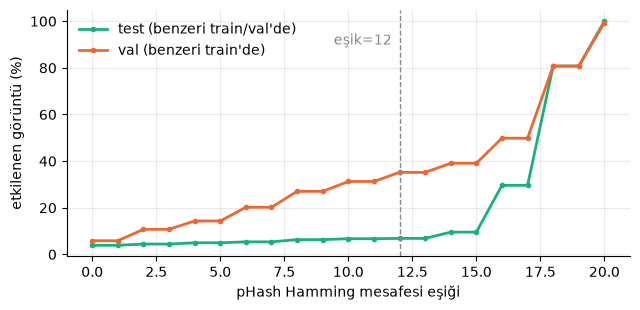

,mesafe,incelenen_cift,ayni_sahne,farkli,not
0,0-4,6,6,0,ilk inceleme paneli (7 Kas 2026)
1,5-8,3,3,0,ilk inceleme paneli
2,9-12,3,3,0,ilk inceleme paneli
3,12,16,16,0,rastgele 16 bölmeler arası çift (random_state=3)
4,14,16,10,6,rastgele 16 çift; farklı olanlar ör. val/angul...
5,16,7,3,4,rastgele örnek; farklı olanlar ör. train/bloss...
6,18-20,8,0,8,rastgele örnek; hepsi farklı fotoğraf


In [11]:
print(summary["duplicates"])
lt = pd.read_csv(C.DERIVED / "leakage_table.csv")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(lt.esik, lt.test_oran * 100, "-o", ms=3, lw=2, color="#1baf7a", label="test (benzeri train/val'de)")
ax.plot(lt.esik, lt.val_oran * 100, "-o", ms=3, lw=2, color="#eb6834", label="val (benzeri train'de)")
ax.axvline(C.PHASH_THRESHOLD, ls="--", color="#898781", lw=1); ax.text(C.PHASH_THRESHOLD - .3, 90, f"eşik={C.PHASH_THRESHOLD}", ha="right", color="#898781")
ax.set_xlabel("pHash Hamming mesafesi eşiği"); ax.set_ylabel("etkilenen görüntü (%)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig(FIG / "sizinti_esik.pdf"); plt.savefig(FIG / "sizinti_esik.png", dpi=200); plt.show()
pd.read_csv(ROOT / "docs" / "phash_calibration.csv")

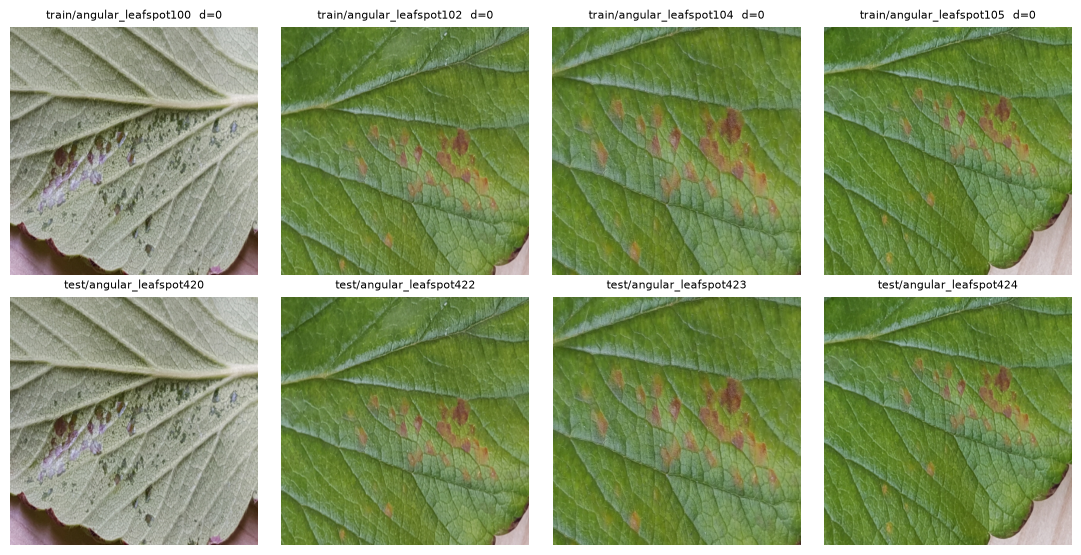

In [12]:
pairs = pd.read_csv(C.DERIVED / "dup_pairs.csv")
ex = pairs[pairs.cross_split & (pairs.dist <= C.PHASH_THRESHOLD) & ((pairs.a_split == "test") | (pairs.b_split == "test"))].head(4)
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for k, (_, r) in enumerate(ex.iterrows()):
    for j, (sp, st) in enumerate(((r.a_split, r.a_stem), (r.b_split, r.b_stem))):
        a = axes[j][k]; a.imshow(Image.open(C.RAW / sp / f"{st}.jpg")); a.axis("off"); a.set_title(f"{sp}/{st}" + (f"  d={r.dist}" if j == 0 else ""), fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "sizinti_ornek.png", dpi=110); plt.show()

## 6 · Dönüşüm doğrulaması

In [13]:
rt = summary["roundtrip"]
print(f"Örnek sayısı           : {rt['n_instances']}")
print(f"IoU (YOLO-seg) min/ort.: {rt['iou_yolo_min']:.4f} / {rt['iou_yolo_mean']:.5f}")
print(f"IoU (COCO)     min/ort.: {rt['iou_coco_min']:.4f} / {rt['iou_coco_mean']:.5f}")
print(f"IoU < 0.99             : {rt['n_iou_lt_0_99']}")
print(f"Sınıf / sayı tutarlı   : {rt['class_ok']} / {rt['count_ok']}")
print("pycocotools yükleme    :", rt["coco_load"])
assert rt["class_ok"] and rt["count_ok"] and rt["n_iou_lt_0_99"] == 0, "Dönüşüm doğrulaması başarısız!"
pd.DataFrame(rt["cls_counts"])

Örnek sayısı           : 5707
IoU (YOLO-seg) min/ort.: 0.9947 / 0.99993
IoU (COCO)     min/ort.: 0.9936 / 0.99995
IoU < 0.99             : 0
Sınıf / sayı tutarlı   : True / True
pycocotools yükleme    : {'train': {'images': 1450, 'annotations': 3540, 'categories': 8}, 'val': {'images': 307, 'annotations': 751, 'categories': 8}, 'test': {'images': 743, 'annotations': 1416, 'categories': 8}}


,train,val,test
Angular Leafspot,245,43,147
Anthracnose Fruit Rot,52,12,33
Blossom Blight,118,29,62
Gray Mold,254,77,145
Leaf Spot,382,71,162
Powdery Mildew Fruit,80,12,43
Powdery Mildew Leaf,319,63,151


## 7 · Tekrarlanabilirlik kaydı

In [14]:
print("Bölme listeleri SHA-256:")
for k, v in summary["split_list_sha256"].items():
    print(f"  {k:10s} {v}")
print("Kaggle zip beklenen SHA-256:", summary["zip_sha256_beklenen"])
print("Süre:", summary["sure_sn"], "sn")

Bölme listeleri SHA-256:
  train      11f2b792587263b4622348f87a8efdc43a524e6f2d49203bb7b4cce02045771b
  val        3e9aa308c3b1c4a6ba1db045017ece7f1a2f707a7f02cec0a2415d944493a72f
  test       dad66fbd7ce8ac0062ab18ac8a6322afd7c1c714cce49671fcb5661aa72c2778
  test_clean b7cf1a5fd165130a2b4b79bd846c6b9222f43afdcc99758a5c0c816a72da9923
Kaggle zip beklenen SHA-256: e728dd56eaab4e11e64d46da77b06eb377beb264c53d0a32c1eaf44d051de525
Süre: 14.0 sn
